# Class 11 Homework: Linear models 

The question in this homework is a little more complicated than in the class.

The question is about the relationship between "file" length and call frequency of bush crickets. Both of these are numerical variables so the analysis is similar to that of rattlesnake temperature. However, plotting these variables reveals that their relationship is non-linear (i.e., they don't form a nice straight line in the graph). So first you have to log-transform the variables before fitting a linear model to them. 


<div class="alert alert-info">
The answers to the questions below are given in blue boxes. These are there to help you write the correct code.
</div>

## Imports

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
from statsmodels.formula.api import ols
from scipy.stats import shapiro


# **Question:** What is the relationship between "file" length and call frequency of bush crickets?

<div>
<img src="Images/fotolia_4278755_XS.jpg" width='50%' title=""/>
</div>

Bush crickets call by rubbing forewings together so that a scrapper on one wing rubs against a file on the other wing. Scientists (Gua et al. 2012) wanted to know what the relationship was between file length and call frequency?

The file `../Datasets/bush_crickets.csv` contains the song frequency (in kilo-Hertz) and file length (in mm) of 58 crickets.

<div class="alert alert-warning">

Use the [workflow_rattlesnakes](workflow_rattlesnakes.ipynb) notebook to help you answer this question. You will also find [Class_10_answers](../Week_05/Class_10_answers.ipynb) helpful for doing Shapiro Wilks tests and log-transforming the data.
</div>

- Read in the data and print it to see what it looks like.

In [2]:
bc = pd.read_csv('../Datasets/bush_crickets.csv')
bc

,songFrequency,fileLength
0,4.7,6.00
1,8.5,6.70
2,8.7,3.80
3,8.7,5.00
4,8.9,2.10
5,9.4,3.00
6,10.9,5.00
7,11.3,1.60
8,11.6,2.60
9,12.7,2.10


- Use an appropriate graph to visually examine the relationship between song frequency and file length.

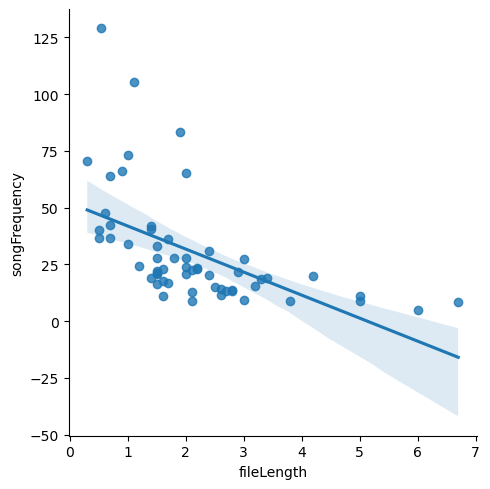

In [3]:
sns.lmplot(x='fileLength', y='songFrequency', data=bc);

Seaborn's regression line does not fit the data well. It also predicts negative song frequencies for file lengths longer than about 5mm, which, of course, is impossible. 

This means that the relationship between file length and song frequency is not a simple straight line, but something more complicated; exponential, quadratic, lograthmic, for example. To try and work out what that relationship is let's first examine if each variable is normally distributed.

- Test if `songFrequency` is normally distributed.
- Test if `fileLength` is normally distributed.

<div class="alert alert-info">

Answer
- song frequency: *P* = $5.2\times 10^{-8}$
- file length: *P* = $7.1\times 10^{-5}$

</div>

In [4]:
print(shapiro(bc['songFrequency']).pvalue)
print(shapiro(bc['fileLength']).pvalue)

5.155468866333372e-08
7.111804982900769e-05


You should find that songFrequency and fileLength are both inconsistent with being normally distributed. In that case let's try log-transforming them both and retesting for normality.

---

- Log-transform songFrequency and fileLength and retest these for normality. It doesn't matter if you use log to base 10 (i.e., `np.log10()`) or log to base *e* (i.e., `np.log()`).

<div class="alert alert-info">

Answer
- song frequency: *P* = 0.63
- file length: *P* = 0.22

</div>

In [5]:
bc['logsongFrequency'] = np.log(bc['songFrequency'])
bc['logfileLength'] = np.log(bc['fileLength'])

print(shapiro(bc['logsongFrequency']).pvalue)
print(shapiro(bc['logfileLength']).pvalue)

0.6302431324920699
0.2173383112918693


You should find that both log-songFrequency and log-fileLength are normally distributed.

- Plot log-songFrequency against log-fileLength to see whether the fit of the regression line improves. 

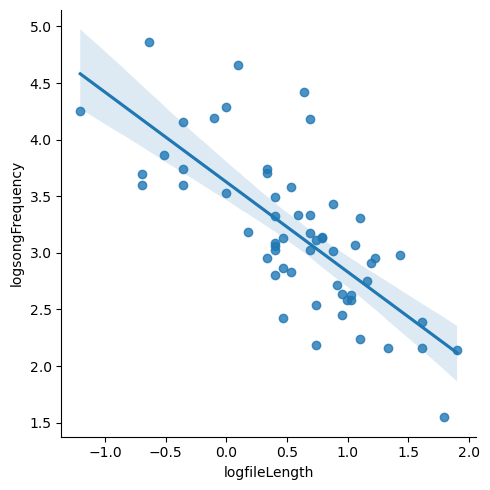

In [6]:
sns.lmplot(x='logfileLength', y='logsongFrequency', data=bc);

You should find that this looks much better with the data now showing a linear relationship.

This means then that the relationship between file length and song frequency has the form

$$
\log(\mathrm{song\ frequency}) = \mathrm{intercept} + \mathrm{slope} \times \log(\mathrm{file\ length})
$$

That is log-song frequency and log-file length are linearly related.

- Write the model formula for the relationship between log-song frequency and log-file length.
- Fit the model.

<div class="alert alert-info">

Answer for log file length
- coef = -0.79
- *t* = -8.4
- *P* = $1.9\times 10^{-11}$
- 95% CI: [-0.98, -0.60] mm


</div>

In [7]:
formula = 'logsongFrequency ~ logfileLength'
fit = ols(formula, bc).fit()
fit.summary().tables[1]

,coef,std err,t,P>|t|,[0.025,0.975]
Intercept,3.6261,0.081,44.661,0.000,3.463,3.789
logfileLength,-0.7935,0.095,-8.377,0.000,-0.983,-0.604


In [8]:
fit.pvalues

Intercept        1.771458e-45
logfileLength    1.858436e-11
dtype: float64

- Write the formula for the numerical relationship between log-song frequency and log-file length using the point estimates from the model fit.

> Write your formula here.

$$
\log(\mathrm{song\ frequency}) = 3.63 - 0.79 \times \log(\mathrm{file\ length})
$$


- Using the laws of logs and laws of exponents rewrite your formula so that it has the form

$$\mathrm{song\ frequency} = A \times \mathrm{file\ length}^{-B}$$

You need to work out the values of $A$ and $B$ from your point estimates of the intercept and slope.

<div class="alert alert-info">

Answer
- *A* = 37.5
- *B* = -0.79

</div>

First use the law $-u\log x = \log x^{-u}$ to give

$$
\log(\mathrm{song\ frequency}) = 3.63 + \log(\mathrm{file\ length}^{-0.79})
$$

Exponentiating both sides gives

$$
\exp(\log(\mathrm{song\ frequency})) = \exp(3.63 + \log(\mathrm{file\ length}^{-0.79}))
$$

The left hand side simplifies,
$$
\mathrm{song\ frequency} = \exp(3.63 + \log(\mathrm{file\ length}^{-0.79}))
$$

Now use the law $\exp(u+v) = \exp(u) \times \exp(v)$ to give

$$
\mathrm{song\ frequency} = \exp(3.63) \times \exp(\log(\mathrm{file\ length}^{-0.79})) \\
$$

Now simplify the right hand side,
$$
\mathrm{song\ frequency} = 37.5 \times \mathrm{file\ length}^{-0.79}
$$



- Report the outcome of the test as you would in a scientific report or paper.

- The fossil of an 165 million year old extinct bush cricket species *Archaboilus musicus* has been discovered. It's file length is 9.34 mm. What was its expected song frequency based on your analysis of living bush crickets?


<div class="alert alert-info">

Answer
- 6.4 kHz
</div>

In [1]:
37.5*9.34**(-0.79)

6.41885012693562